In [1]:
!pip install -q kagglehub shap xgboost openpyxl

In [2]:
import kagglehub, glob, os, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)

path = kagglehub.dataset_download("ankitverma2010/ecommerce-customer-churn-analysis-and-prediction")
files = glob.glob(os.path.join(path, "**", "*.xlsx"), recursive=True)
print("Bulunan dosyalar:", files)

df = pd.read_excel(files[0], sheet_name="E Comm")
print(df.shape)
df.head()

100%|██████████| 532k/532k [00:00<00:00, 670kB/s]

Extracting files...


Bulunan dosyalar: ['/root/.cache/kagglehub/datasets/ankitverma2010/ecommerce-customer-churn-analysis-and-prediction/versions/1/E Commerce Dataset.xlsx']
(5630, 20)


,CustomerID,Churn,Tenure,PreferredLoginDevice,CityTier,WarehouseToHome,PreferredPaymentMode,Gender,HourSpendOnApp,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,OrderAmountHikeFromlastYear,CouponUsed,OrderCount,DaySinceLastOrder,CashbackAmount
0,50001,1,4.0,Mobile Phone,3,6.0,Debit Card,Female,3.0,3,Laptop & Accessory,2,Single,9,1,11.0,1.0,1.0,5.0,159.93
1,50002,1,NaN,Phone,1,8.0,UPI,Male,3.0,4,Mobile,3,Single,7,1,15.0,0.0,1.0,0.0,120.90
2,50003,1,NaN,Phone,1,30.0,Debit Card,Male,2.0,4,Mobile,3,Single,6,1,14.0,0.0,1.0,3.0,120.28
3,50004,1,0.0,Phone,3,15.0,Debit Card,Male,2.0,4,Laptop & Accessory,5,Single,8,0,23.0,0.0,1.0,3.0,134.07
4,50005,1,0.0,Phone,1,12.0,CC,Male,NaN,3,Mobile,5,Single,3,0,11.0,1.0,1.0,3.0,129.60


In [3]:
df.info()

print("\nChurn oranı:", round(df.Churn.mean(), 3))

for c in ["PreferredLoginDevice", "PreferredPaymentMode", "PreferedOrderCat", "Gender", "MaritalStatus"]:
    print("\n", c)
    print(df[c].value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5630 entries, 0 to 5629
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   CustomerID                   5630 non-null   int64  
 1   Churn                        5630 non-null   int64  
 2   Tenure                       5366 non-null   float64
 3   PreferredLoginDevice         5630 non-null   object 
 4   CityTier                     5630 non-null   int64  
 5   WarehouseToHome              5379 non-null   float64
 6   PreferredPaymentMode         5630 non-null   object 
 7   Gender                       5630 non-null   object 
 8   HourSpendOnApp               5375 non-null   float64
 9   NumberOfDeviceRegistered     5630 non-null   int64  
 10  PreferedOrderCat             5630 non-null   object 
 11  SatisfactionScore            5630 non-null   int64  
 12  MaritalStatus                5630 non-null   object 
 13  NumberOfAddress   

In [4]:
df["PreferredLoginDevice"] = df["PreferredLoginDevice"].replace({"Phone": "Mobile Phone"})
df["PreferredPaymentMode"] = df["PreferredPaymentMode"].replace({"CC": "Credit Card", "COD": "Cash on Delivery"})
df["PreferedOrderCat"]     = df["PreferedOrderCat"].replace({"Mobile": "Mobile Phone"})

for c in ["PreferredLoginDevice", "PreferredPaymentMode", "PreferedOrderCat"]:
    print("\n", c)
    print(df[c].value_counts())


 PreferredLoginDevice
PreferredLoginDevice
Mobile Phone    3996
Computer        1634
Name: count, dtype: int64

 PreferredPaymentMode
PreferredPaymentMode
Debit Card          2314
Credit Card         1774
E wallet             614
Cash on Delivery     514
UPI                  414
Name: count, dtype: int64

 PreferedOrderCat
PreferedOrderCat
Mobile Phone          2080
Laptop & Accessory    2050
Fashion                826
Grocery                410
Others                 264
Name: count, dtype: int64


In [5]:
print("Eksik değerler:")
print(df.isna().sum()[df.isna().sum() > 0])

feat = [c for c in df.columns if c not in ("CustomerID", "Churn")]
print("\nID dışında birebir kopya satır sayısı:", df.duplicated(subset=feat + ["Churn"]).sum())

# Eksik olmanın kendisi churn ile ilişkili mi?
for c in df.columns[df.isna().any()]:
    print(f"{c:30s} eksikken churn: {df[df[c].isna()].Churn.mean():.3f} | doluyken: {df[df[c].notna()].Churn.mean():.3f}")

Eksik değerler:
Tenure                         264
WarehouseToHome                251
HourSpendOnApp                 255
OrderAmountHikeFromlastYear    265
CouponUsed                     256
OrderCount                     258
DaySinceLastOrder              307
dtype: int64

ID dışında birebir kopya satır sayısı: 557
Tenure                         eksikken churn: 0.307 | doluyken: 0.162
WarehouseToHome                eksikken churn: 0.335 | doluyken: 0.161
HourSpendOnApp                 eksikken churn: 0.227 | doluyken: 0.166
OrderAmountHikeFromlastYear    eksikken churn: 0.053 | doluyken: 0.174
CouponUsed                     eksikken churn: 0.031 | doluyken: 0.175
OrderCount                     eksikken churn: 0.070 | doluyken: 0.173
DaySinceLastOrder              eksikken churn: 0.176 | doluyken: 0.168


In [6]:
base = df.Churn.mean()
for c in ["Complain", "SatisfactionScore", "CityTier", "PreferedOrderCat",
          "PreferredPaymentMode", "MaritalStatus", "NumberOfDeviceRegistered"]:
    print("\n", c)
    print(df.groupby(c).Churn.agg(["mean", "count"]).round(3))

bins = {
    "Tenure": [-1, 0, 1, 3, 6, 12, 24, 100],
    "DaySinceLastOrder": [-1, 0, 2, 5, 10, 50],
    "CashbackAmount": [0, 130, 150, 170, 200, 400],
    "WarehouseToHome": [0, 10, 15, 20, 30, 200],
}
for c, b in bins.items():
    print("\n", c)
    print(df.groupby(pd.cut(df[c], b)).Churn.agg(["mean", "count"]).round(3))


 Complain
           mean  count
Complain              
0         0.109   4026
1         0.317   1604

 SatisfactionScore
                    mean  count
SatisfactionScore              
1                  0.115   1164
2                  0.126    586
3                  0.172   1698
4                  0.171   1074
5                  0.238   1108

 CityTier
           mean  count
CityTier              
1         0.145   3666
2         0.198    242
3         0.214   1722

 PreferedOrderCat
                     mean  count
PreferedOrderCat                
Fashion             0.155    826
Grocery             0.049    410
Laptop & Accessory  0.102   2050
Mobile Phone        0.274   2080
Others              0.076    264

 PreferredPaymentMode
                       mean  count
PreferredPaymentMode              
Cash on Delivery      0.249    514
Credit Card           0.142   1774
Debit Card            0.154   2314
E wallet              0.228    614
UPI                   0.174    414

 Marital

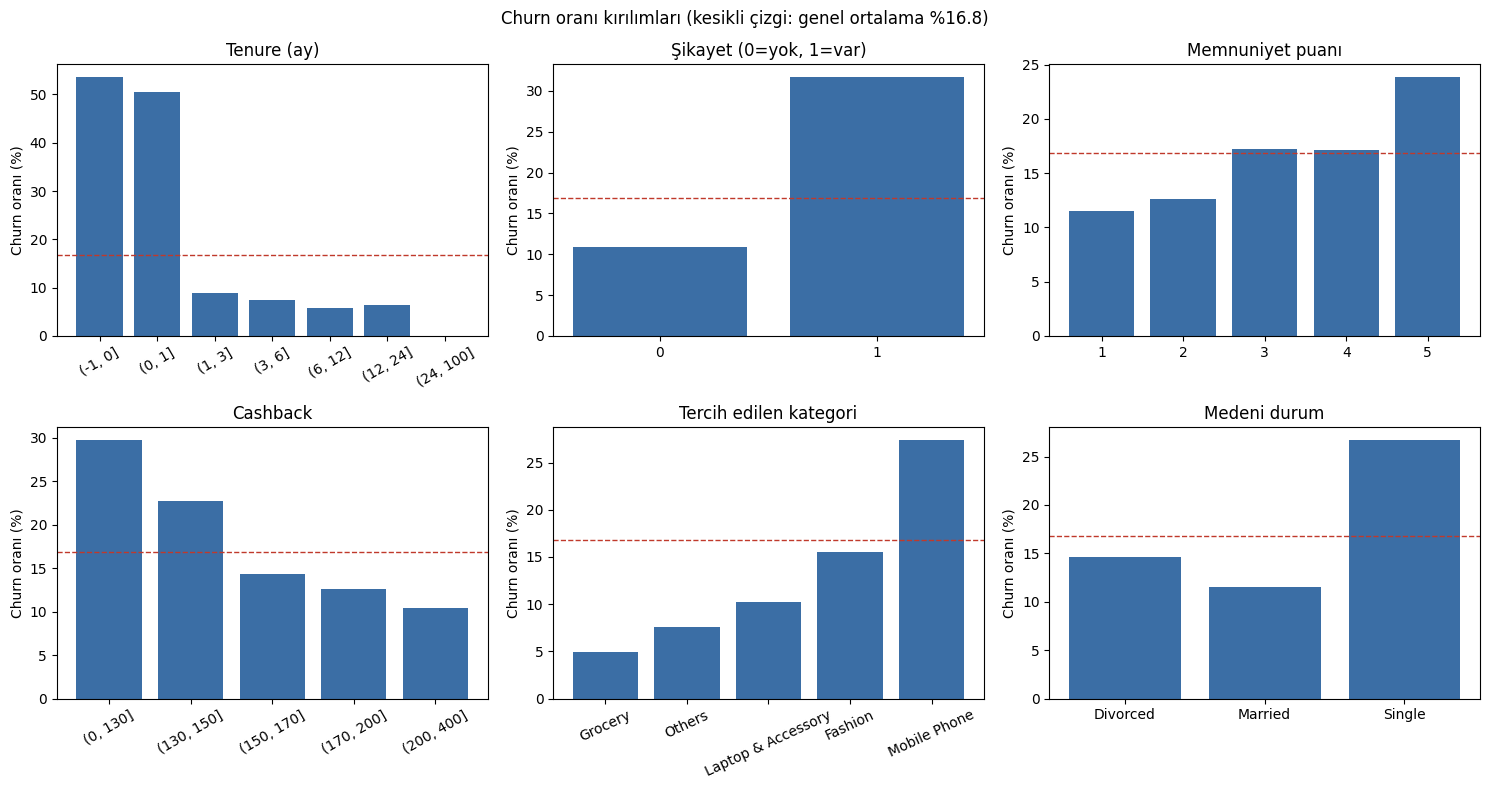

In [7]:
fig, ax = plt.subplots(2, 3, figsize=(15, 8))

def bar(a, s, title, rot=0):
    a.bar(s.index.astype(str), s.values * 100, color="#3b6ea5")
    a.axhline(base * 100, color="#c0392b", ls="--", lw=1)
    a.set_title(title); a.set_ylabel("Churn oranı (%)"); a.tick_params(axis="x", rotation=rot)

bar(ax[0,0], df.groupby(pd.cut(df.Tenure, bins["Tenure"])).Churn.mean(), "Tenure (ay)", 30)
bar(ax[0,1], df.groupby("Complain").Churn.mean(), "Şikayet (0=yok, 1=var)")
bar(ax[0,2], df.groupby("SatisfactionScore").Churn.mean(), "Memnuniyet puanı")
bar(ax[1,0], df.groupby(pd.cut(df.CashbackAmount, bins["CashbackAmount"])).Churn.mean(), "Cashback", 30)
bar(ax[1,1], df.groupby("PreferedOrderCat").Churn.mean().sort_values(), "Tercih edilen kategori", 25)
bar(ax[1,2], df.groupby("MaritalStatus").Churn.mean(), "Medeni durum")
plt.suptitle(f"Churn oranı kırılımları (kesikli çizgi: genel ortalama %{base*100:.1f})")
plt.tight_layout(); plt.show()

In [8]:
from sklearn.model_selection import GroupShuffleSplit

cat_cols = ["PreferredLoginDevice", "PreferredPaymentMode", "PreferedOrderCat", "Gender", "MaritalStatus"]
X = df[feat].copy()
for c in X.columns[X.isna().any()]:
    X[c + "_missing"] = X[c].isna().astype(int)
X = pd.get_dummies(X, columns=cat_cols, dtype=int)
y = df.Churn

groups = df.groupby(feat + ["Churn"], dropna=False).ngroup().values
tr, te = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42).split(X, y, groups))
Xtr, Xte, ytr, yte = X.iloc[tr], X.iloc[te], y.iloc[tr], y.iloc[te]

med = Xtr.median()
Xtr, Xte = Xtr.fillna(med), Xte.fillna(med)
print("Eğitim:", Xtr.shape, "| Test:", Xte.shape, "| Test churn oranı:", round(yte.mean(), 3))

Eğitim: (4499, 37) | Test: (1131, 37) | Test churn oranı: 0.193


In [9]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, precision_score, recall_score, f1_score
from xgboost import XGBClassifier

spw = (ytr == 0).sum() / (ytr == 1).sum()
scaler = StandardScaler().fit(Xtr)

lr  = LogisticRegression(max_iter=3000, class_weight="balanced").fit(scaler.transform(Xtr), ytr)
rf  = RandomForestClassifier(n_estimators=400, min_samples_leaf=2, class_weight="balanced_subsample",
                             random_state=42, n_jobs=-1).fit(Xtr, ytr)
xgb = XGBClassifier(n_estimators=400, max_depth=4, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
                    scale_pos_weight=spw, eval_metric="logloss", random_state=42, n_jobs=-1).fit(Xtr, ytr)

probs = {
    "Logistic Regression": lr.predict_proba(scaler.transform(Xte))[:, 1],
    "Random Forest": rf.predict_proba(Xte)[:, 1],
    "XGBoost": xgb.predict_proba(Xte)[:, 1],
}
rows = []
for name, p in probs.items():
    pred = (p >= 0.5).astype(int)
    rows.append(dict(Model=name, ROC_AUC=roc_auc_score(yte, p), PR_AUC=average_precision_score(yte, p),
                     Precision=precision_score(yte, pred), Recall=recall_score(yte, pred), F1=f1_score(yte, pred)))
results = pd.DataFrame(rows).round(3)
print("Rastgele tahminin PR-AUC değeri (churn oranı):", round(yte.mean(), 3))
results

Rastgele tahminin PR-AUC değeri (churn oranı): 0.193


,Model,ROC_AUC,PR_AUC,Precision,Recall,F1
0,Logistic Regression,0.894,0.726,0.510,0.826,0.630
1,Random Forest,0.972,0.918,0.876,0.812,0.843
2,XGBoost,0.965,0.883,0.772,0.853,0.810


In [10]:
p = probs["Random Forest"]
print("Eşik | Precision | Recall | İşaretlenen müşteri")
for t in (0.2, 0.3, 0.4, 0.5, 0.6):
    pr = (p >= t).astype(int)
    print(f"{t:.1f}  |   {precision_score(yte, pr):.3f}   | {recall_score(yte, pr):.3f}  | {pr.sum()}")

d = pd.DataFrame({"p": p, "y": yte.values}).sort_values("p", ascending=False)
k = int(len(d) * 0.1)
top = d.iloc[:k]
print(f"\nEn riskli %10: churn oranı {top.y.mean():.3f} | lift {top.y.mean()/yte.mean():.1f}x | "
      f"tüm churn'lerin %{top.y.sum()/d.y.sum()*100:.0f}'ini yakalıyor")

Eşik | Precision | Recall | İşaretlenen müşteri
0.2  |   0.618   | 0.950  | 335
0.3  |   0.725   | 0.908  | 273
0.4  |   0.823   | 0.872  | 231
0.5  |   0.876   | 0.812  | 202
0.6  |   0.954   | 0.665  | 152

En riskli %10: churn oranı 0.982 | lift 5.1x | tüm churn'lerin %51'ini yakalıyor


Tenure                                 1.828
Complain                               0.741
NumberOfAddress                        0.545
CashbackAmount                         0.463
DaySinceLastOrder                      0.359
CityTier                               0.347
WarehouseToHome                        0.318
SatisfactionScore                      0.316
MaritalStatus_Single                   0.299
PreferedOrderCat_Laptop & Accessory    0.272
NumberOfDeviceRegistered               0.254
OrderCount                             0.197
dtype: float32


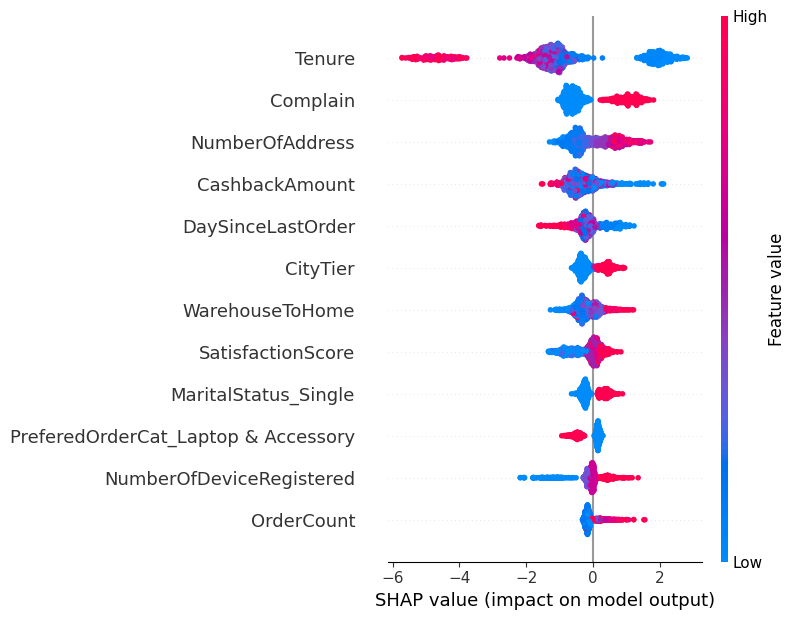

In [11]:
import shap
sv = shap.TreeExplainer(xgb).shap_values(Xte)

imp = pd.Series(np.abs(sv).mean(0), index=Xte.columns).sort_values(ascending=False)
print(imp.head(12).round(3))

shap.summary_plot(sv, Xte, max_display=12)

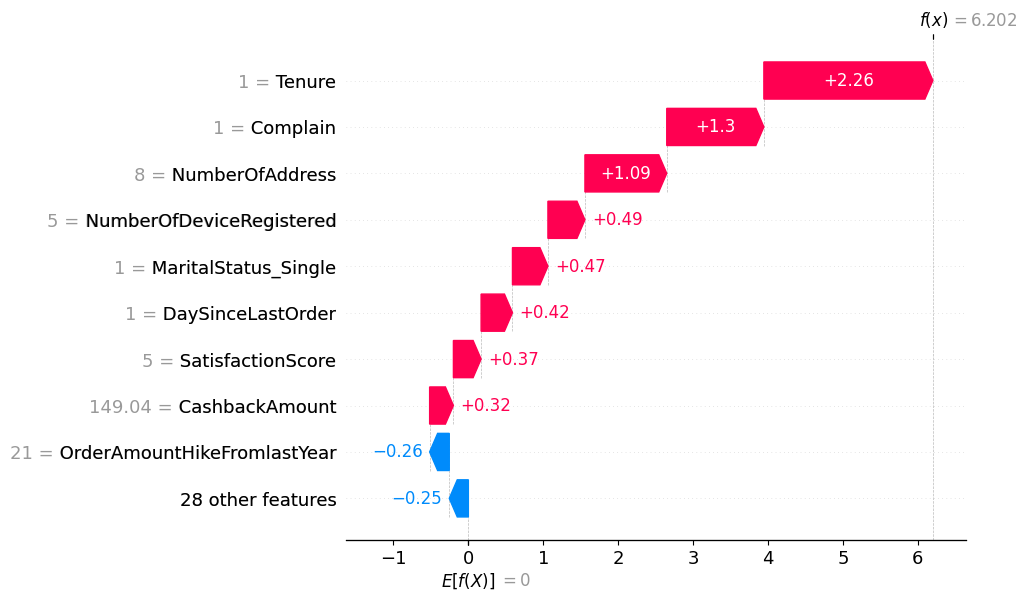

In [12]:
i = int(np.argmax(probs["XGBoost"]))
base_val = float(np.ravel(shap.TreeExplainer(xgb).expected_value)[0])
exp = shap.Explanation(values=sv[i], base_values=base_val,
                       data=Xte.iloc[i].values, feature_names=list(Xte.columns))
shap.plots.waterfall(exp, max_display=10)

In [13]:
from sklearn.inspection import permutation_importance

r = permutation_importance(xgb, Xte, yte, scoring="average_precision",
                           n_repeats=10, random_state=42, n_jobs=-1)
perm = pd.Series(r.importances_mean, index=Xte.columns).sort_values(ascending=False)
print("Permutation importance (PR-AUC düşüşü), ilk 10:")
print(perm.head(10).round(4))

Permutation importance (PR-AUC düşüşü), ilk 10:
Tenure                      0.4537
Complain                    0.1278
NumberOfAddress             0.0923
SatisfactionScore           0.0510
WarehouseToHome             0.0452
CashbackAmount              0.0428
DaySinceLastOrder           0.0304
MaritalStatus_Single        0.0264
NumberOfDeviceRegistered    0.0226
CityTier                    0.0204
dtype: float64


In [14]:
def fit_score(cols):
    m = XGBClassifier(n_estimators=200, max_depth=4, learning_rate=0.08, subsample=0.8, colsample_bytree=0.8,
                      scale_pos_weight=spw, eval_metric="logloss", random_state=42, n_jobs=-1)
    m.fit(Xtr[cols], ytr)
    return average_precision_score(yte, m.predict_proba(Xte[cols])[:, 1])

all_cols = list(Xtr.columns)
ref = fit_score(all_cols)
drops = {}
for f in feat:
    group = [c for c in all_cols if c == f or c.startswith(f + "_")]
    drops[f] = ref - fit_score([c for c in all_cols if c not in group])

drop_df = pd.Series(drops).sort_values(ascending=False).round(4)
print(f"Referans PR-AUC: {ref:.3f}")
print("Sütun çıkarılınca PR-AUC kaybı (büyük = önemli):")
print(drop_df)

Referans PR-AUC: 0.882
Sütun çıkarılınca PR-AUC kaybı (büyük = önemli):
Tenure                         0.1051
Complain                       0.0511
NumberOfAddress                0.0437
SatisfactionScore              0.0349
CashbackAmount                 0.0234
MaritalStatus                  0.0221
WarehouseToHome                0.0206
PreferredLoginDevice           0.0178
PreferredPaymentMode           0.0164
CityTier                       0.0143
DaySinceLastOrder              0.0132
PreferedOrderCat               0.0120
NumberOfDeviceRegistered       0.0084
OrderAmountHikeFromlastYear    0.0042
CouponUsed                     0.0033
Gender                         0.0028
HourSpendOnApp                 0.0023
OrderCount                    -0.0019
dtype: float64
